PROYECTO APRENDIZAJE DE MÁQUINA

Este proyecto consiste en crear un modelo que prediga los gastos médicos de una persona a partir de su edad, IMC, tabaquismo, número de hijos y región, haciendo uso de un csv descargado de Kaggle.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# Cargar los datos
df = pd.read_csv('insurance.csv')

print("Dataset cargado correctamente")
print("Filas y columnas:", df.shape)

display(df.head())

Dataset cargado correctamente
Filas y columnas: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
# 1. Revisar los tipos de datos y valores faltantes
print("Información del dataset:")
df.info()

print("\nValores faltantes por columna:")
print(df.isnull().sum())

print("\nFilas duplicadas:", df.duplicated().sum())

print("\nEstadísticas de las variables numéricas:")
display(df.describe())

print("\nDistribución de los gastos médicos:")
display(df["charges"].describe())


Información del dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

Valores faltantes por columna:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Filas duplicadas: 1

Estadísticas de las variables numéricas:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010



Distribución de los gastos médicos:


count     1338.000000
mean     13270.422265
std      12110.011237
min       1121.873900
25%       4740.287150
50%       9382.033000
75%      16639.912515
max      63770.428010
Name: charges, dtype: float64

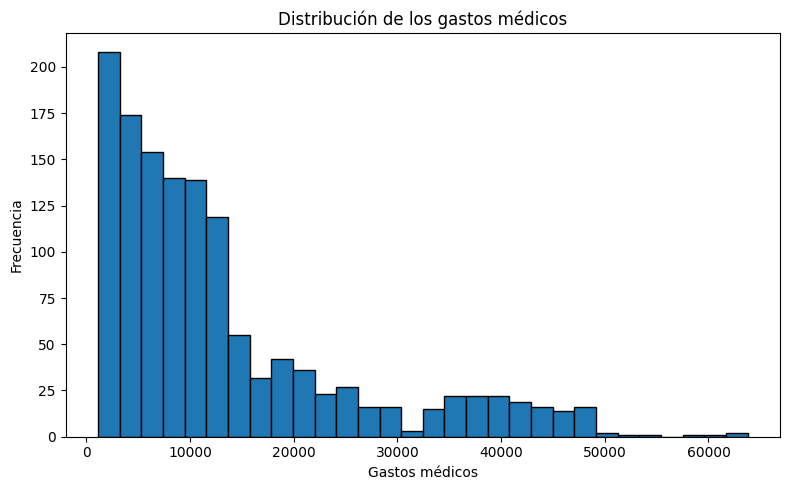

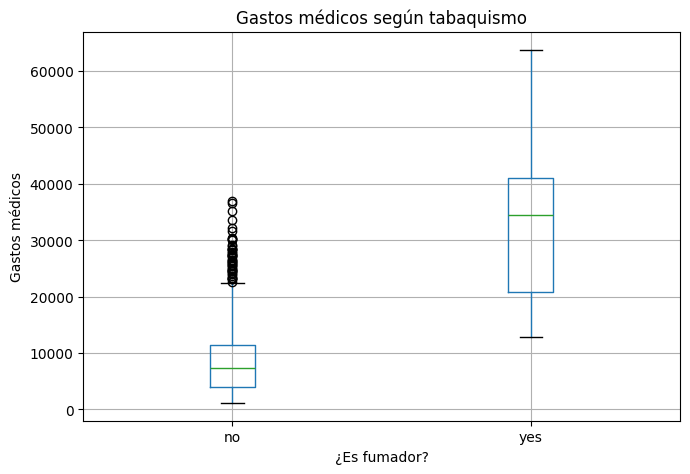

In [4]:
# Distribución de los gastos médicos
plt.figure(figsize=(8, 5))
plt.hist(df["charges"], bins=30, edgecolor="black")
plt.title("Distribución de los gastos médicos")
plt.xlabel("Gastos médicos")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

# Comparar gastos médicos según tabaquismo
df.boxplot(column="charges", by="smoker", figsize=(7, 5))
plt.title("Gastos médicos según tabaquismo")
plt.suptitle("")
plt.xlabel("¿Es fumador?")
plt.ylabel("Gastos médicos")
plt.tight_layout()
plt.show()


In [5]:
# Separar las variables predictoras de la variable objetivo
X = df.drop(columns=["charges"]).copy()
y = df["charges"].copy()

# Identificar columnas numéricas y categóricas
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Variables predictoras:", X.columns.tolist())
print("Variables numéricas:", numeric_features)
print("Variables categóricas:", categorical_features)

print("\nVariable objetivo: charges")
print("Total de registros:", len(df))

Variables predictoras: ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
Variables numéricas: ['age', 'bmi', 'children']
Variables categóricas: ['sex', 'smoker', 'region']

Variable objetivo: charges
Total de registros: 1338


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

# 1. Procesamiento de variables numéricas
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 2. Procesamiento de variables categóricas
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# 3. Combinar los procesamientos
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# 4. Crear el pipeline completo
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])

print("Pipeline creado correctamente")
print(pipeline)

Pipeline creado correctamente
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                         

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Datos separados correctamente")
print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)


Datos separados correctamente
Datos de entrenamiento: (1070, 6)
Datos de prueba: (268, 6)


In [8]:
from sklearn.model_selection import GridSearchCV, KFold

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_pipeline = grid_search.best_estimator_

print("\nMejores parámetros:")
print(grid_search.best_params_)

print("\nMAE promedio en validación cruzada:")
print(round(-grid_search.best_score_, 2))


Fitting 5 folds for each of 12 candidates, totalling 60 fits

Mejores parámetros:
{'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 100}

MAE promedio en validación cruzada:
2714.2


In [9]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Generar predicciones sobre datos que no vio durante el entrenamiento
y_pred = best_pipeline.predict(X_test)

# Calcular métricas de evaluación
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("===== EVALUACIÓN DEL MODELO =====")
print(f"MAE:  ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R²:    {r2:.4f}")

===== EVALUACIÓN DEL MODELO =====
MAE:  $2,532.45
RMSE: $4,524.25
R²:    0.8682


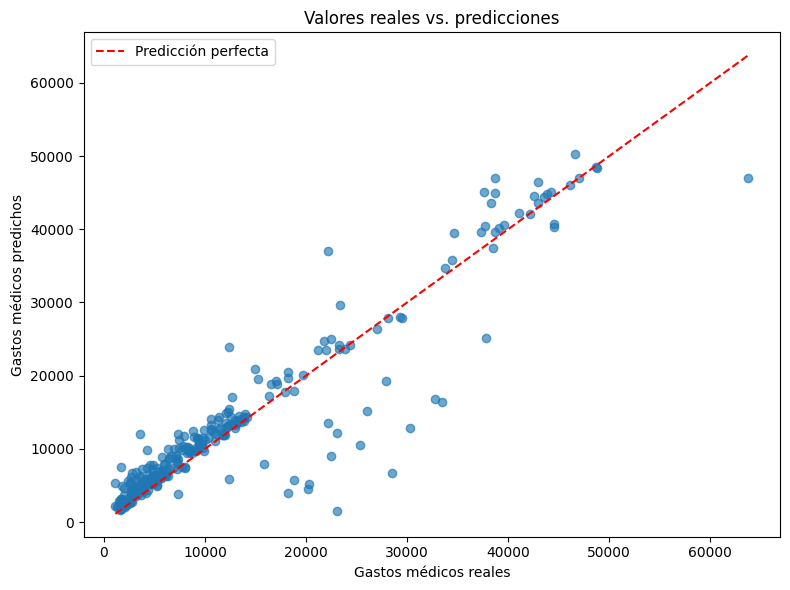

In [10]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.65)

# Línea de predicción perfecta
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Predicción perfecta"
)

plt.xlabel("Gastos médicos reales")
plt.ylabel("Gastos médicos predichos")
plt.title("Valores reales vs. predicciones")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
import joblib

# Guardar el pipeline ya entrenado y optimizado
joblib.dump(
    best_pipeline,
    "modelo_gastos_medicos.pkl"
)

print("¡Pipeline exportado correctamente!")
print("Archivo: modelo_gastos_medicos.pkl")

¡Pipeline exportado correctamente!
Archivo: modelo_gastos_medicos.pkl
